# Week 1.4 - Spectral and discontinuous Galerkin methods on CPU

**A numerical-methods extension after Week 1.2: SIMPLE, PISO and PIMPLE.**

[Open in Google Colab](https://colab.research.google.com/github/Ehsan-Roohi/FlowMLLab/blob/main/notebooks/week01_4/W1_4_Spectral_DG_CPU.ipynb) · [Lecture PDF](../../lectures/week01_4_spectral_dg.pdf) · [Setup and learning route](README.md) · [Previous pressure-velocity lab](../week01_2/W1_2_Cavity_Pressure_Velocity.ipynb)

**Question:** how does the spatial approximation change accuracy, conservation and cost?
We implement the algorithms below, not merely call an external CFD package.
NumPy, SciPy, Matplotlib and pandas are sufficient; no GPU, MPI, training data or cluster is needed.

**Route:** sections 1-4 (Chebyshev/Poisson), 5-9 (DG/transport), 10 (actual cavity CFD), 11-12 (exercises and evidence).
Plan two teaching sessions plus independent exercises; this is a teaching allocation, not a measured study time.
Run All recomputes every displayed experiment. The output timings describe your computer.

By the end you should be able to:
1. Build a differentiation matrix and impose boundary values.
2. Explain global polynomial approximation versus cell-local polynomials.
3. Derive a conservative DG numerical flux and identify the finite-volume limit.
4. Separate spatial, temporal, quadrature and algebraic error.
5. Choose a method using field/profile errors and computational work.
6. Solve a steady lid-driven cavity on CPU and compare computed velocities with Ghia.

Sections 1-9 verify spatial/time operators on manufactured pressure and passive-scalar transport.
Section 10 then solves the actual incompressible cavity at Re=100 and 400 using Chebyshev collocation.
Keep these three physical problems and their validation criteria distinct.

## 1. Setup and controlled experiments

Use Python 3.10-3.13. If imports are missing, run `%pip install numpy scipy matplotlib pandas`
in a separate cell, restart the kernel, and run from the top. Colab normally provides these packages.
The notebook contains its own solver definitions and needs no repository clone or downloaded fields.

All lengths below are nondimensional. The pressure problem has a unit square and prescribed
zero boundary pressure. The transport problem has unit period, speed $a=1$ and final time $t=0.35$.
There is no Reynolds number in these scalar verification problems.

Change controls in the named experiment cell, then rerun the cells below it.
Keep the exact solution, evaluation locations and error norm fixed when comparing methods.

In [1]:
from pathlib import Path
from time import perf_counter
import os, sys, json, platform
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from numpy.polynomial.legendre import leggauss, legvander
from scipy.interpolate import BarycentricInterpolator, RegularGridInterpolator
from scipy.linalg import solve_sylvester, solve
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import spsolve
from IPython.display import display

OUTPUT_DIR = Path(os.environ.get("FLOWMLLAB_W14_OUTPUT", "week01_4_output"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "DejaVu Serif"],
                     "font.size": 11, "axes.labelsize": 12, "legend.fontsize": 10,
                     "figure.dpi": 120, "savefig.dpi": 180, "axes.spines.top": False,
                     "axes.spines.right": False, "mathtext.fontset": "stix"})
COLORS = ["#0755a1", "#11855a", "#c73735", "#6a3b9a"]
FIGURES = []
def save_figure(fig, name):
    fig.savefig(OUTPUT_DIR / (name + ".png"), bbox_inches="tight", facecolor="white")
    fig.savefig(OUTPUT_DIR / (name + ".pdf"), bbox_inches="tight", facecolor="white")
    FIGURES.append(name)
    plt.show()
    plt.close(fig)

RUN_STARTED = perf_counter()
print("CPU notebook | Python", platform.python_version(), "| NumPy", np.__version__, "| SciPy", scipy.__version__)

CPU notebook | Python 3.12.14 | NumPy 2.2.6 | SciPy 1.15.3


## 2. From finite differences to Chebyshev collocation

With $N+1$ nodes on $[0,1]$, let $x_j=(1-\cos(j\pi/N))/2$, $j=0,\ldots,N$.
The nodes cluster near the walls. The polynomial $q_N(x)=\sum_j q_j\ell_j(x)$
passes through every sample; $\ell_j$ is the $j$th Lagrange cardinal polynomial.
Then $q'_N(x_i)=\sum_j D_{ij}q_j$ with $D_{ij}=\ell'_j(x_i)$.

For $i\ne j$, $D_{ij}=w_j/[w_i(x_i-x_j)]$, with $w_j=(-1)^j$ and endpoint
weights halved. Set $D_{ii}=-\sum_{j\ne i}D_{ij}$ so a constant differentiates to zero.
The matrix differentiates with respect to **x on [0,1]**, not the reference coordinate on [-1,1].

Compare two targets: $q_s=\sin(2\pi x)+0.2\cos(6\pi x)$ and $q_c=|x-0.37|$.
The second has a corner. Smoothness is a property of the solution, not the plotting grid.

In [2]:
def chebyshev_grid(n):
    """n+1 increasing Lobatto nodes on [0,1] and their first derivative matrix."""
    if not isinstance(n, (int, np.integer)) or n < 2:
        raise ValueError("n must be an integer >= 2")
    x = (1 - np.cos(np.pi * np.arange(n + 1) / n)) / 2
    weights = (-1.0) ** np.arange(n + 1)
    weights[[0, -1]] *= 0.5
    delta = x[:, None] - x[None, :]
    np.fill_diagonal(delta, 1.0)
    d = (weights[None, :] / weights[:, None]) / delta
    np.fill_diagonal(d, 0.0)
    np.fill_diagonal(d, -d.sum(axis=1))
    return x, d


def interpolate_chebyshev(x, values, query, axis=0):
    """Evaluate the nodal polynomial with explicit Lobatto barycentric weights."""
    w = (-1.0) ** np.arange(len(x))
    w[[0, -1]] *= 0.5
    return BarycentricInterpolator(x, values, axis=axis, wi=w)(query)


def interpolate_field(x, field, query, method):
    """All fields use array indexing field[y_index, x_index]."""
    if method == "chebyshev":
        intermediate = interpolate_chebyshev(x, field, query, axis=1)
        return interpolate_chebyshev(x, intermediate, query, axis=0)
    if method == "finite_difference":
        yy, xx = np.meshgrid(query, query, indexing="ij")
        return RegularGridInterpolator((x, x), field)(np.stack((yy, xx), axis=-1))
    raise ValueError("Unknown spatial method")

,target,N,nodes,max_error_2001_points
Table A: interpolation,,,,
0,Smooth,8,9,1.378549e-01
1,Corner,8,9,5.196741e-02
2,Smooth,12,13,5.221468e-03
3,Corner,12,13,2.405229e-02
4,Smooth,16,17,4.929023e-05
5,Corner,16,17,2.642272e-02
6,Smooth,24,25,2.744711e-10
7,Corner,24,25,1.190976e-02
8,Smooth,32,33,9.992007e-16


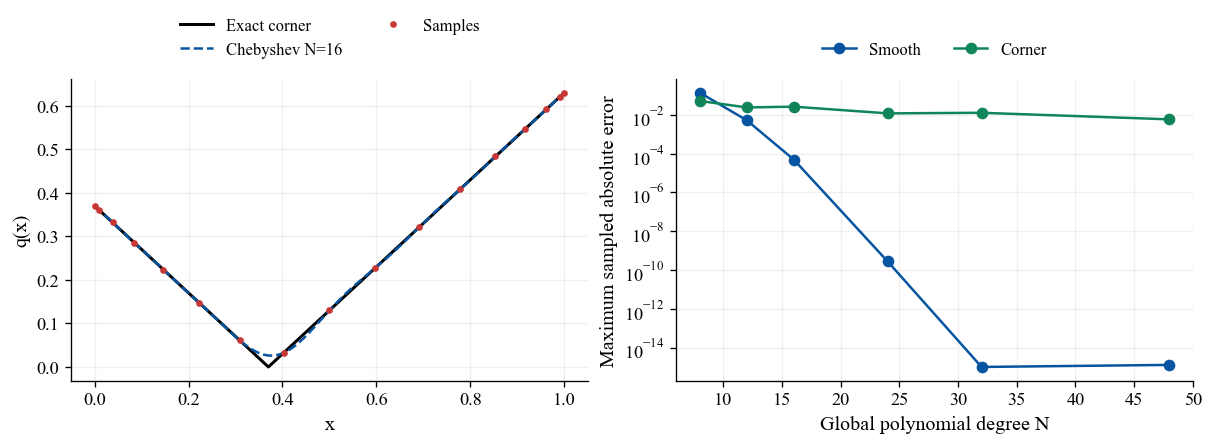

In [3]:
# Experiment A controls: N is the global polynomial degree (N+1 nodes).
DEGREES = [8, 12, 16, 24, 32, 48]
N_SHOW = 16
fine_x = np.linspace(0, 1, 2001)
targets = {"Smooth": lambda x: np.sin(2*np.pi*x)+0.2*np.cos(6*np.pi*x),
           "Corner": lambda x: np.abs(x-0.37)}
rows_a = []
for n in DEGREES:
    xc, d = chebyshev_grid(n)
    assert np.max(np.abs(d @ xc**3 - 3*xc**2)) < 1e-9
    for name, fun in targets.items():
        error = interpolate_chebyshev(xc, fun(xc), fine_x) - fun(fine_x)
        rows_a.append({"target": name, "N": n, "nodes": n+1,
                       "max_error_2001_points": np.max(np.abs(error))})
table_a = pd.DataFrame(rows_a)
display(table_a.rename_axis("Table A: interpolation"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
xc, _ = chebyshev_grid(N_SHOW)
axes[0].plot(fine_x, targets["Corner"](fine_x), "k-", lw=1.8, label="Exact corner")
axes[0].plot(fine_x, interpolate_chebyshev(xc, targets["Corner"](xc), fine_x),
             color=COLORS[0], ls="--", label=f"Chebyshev N={N_SHOW}")
axes[0].plot(xc, targets["Corner"](xc), "o", color=COLORS[2], ms=3, label="Samples")
axes[0].set(xlabel="x", ylabel="q(x)")
for color, (name, group) in zip(COLORS, table_a.groupby("target", sort=False)):
    axes[1].semilogy(group["N"], group["max_error_2001_points"], "o-", color=color, label=name)
axes[1].set(xlabel="Global polynomial degree N", ylabel="Maximum sampled absolute error")
for ax in axes:
    ax.grid(alpha=0.18)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False, ncol=2)
save_figure(fig, "interpolation_smoothness")

**Read Figure A.** The smooth target can converge rapidly until floating-point accuracy becomes relevant.
The corner remains difficult even at larger $N$. A denser plotting grid does not add degrees of freedom.
The sampled maximum is a reproducible error diagnostic, not a proof of the continuous supremum.

**Checkpoint A:** Why does making $D\mathbf{1}=0$ matter? Explain why a small interpolation error
does not guarantee an equally small derivative error near a corner. Exercise 1 tests both claims.

## 3. A two-dimensional Poisson problem with a known answer

Choose $p^*(x,y)=\sin(\pi x)\sin(2\pi y)$, so
$$\nabla^2p^*=f,\qquad f=-5\pi^2\sin(\pi x)\sin(2\pi y),\qquad p^*|_{\partial\Omega}=0.$$
Here $p^*$ is a nondimensional manufactured pressure; $f$ is a prescribed source and
$\Omega=[0,1]^2$. No density, lid speed or Reynolds number is inferred from this field.

Let $A=(D^2)_{I,I}$ for interior indices $I=1,\ldots,N-1$.
With array convention $P_{j,i}=p^*(x_i,y_j)$, solve
$$AP+PA^T=F.$$
This Sylvester equation avoids forming a dense $(N-1)^2$ by $(N-1)^2$ matrix.
Zero boundary values make the right-hand-side correction zero; **nonzero Dirichlet data
would require subtracting the known boundary contributions before solving**.

The comparison uses a second-order central finite-difference Laplacian on an equispaced
grid with the same number of interior unknowns. Its Kronecker-sum matrix is sparse.
Both solve the same PDE and boundary conditions; neither uses a pressure-velocity loop here.

In [4]:
def exact_pressure(x, y):
    """Manufactured nondimensional pressure, zero on the unit-square boundary."""
    return np.sin(np.pi * x) * np.sin(2 * np.pi * y)


def poisson_square(n=16, method="chebyshev"):
    """Solve Laplacian(p) = -5*pi**2*p_exact, with prescribed p=0 on walls.

    This Dirichlet manufactured problem verifies a spatial Poisson operator.
    It is NOT the physical pressure boundary condition of a driven cavity.
    Timings include assembly + solve; plotting and error interpolation excluded.
    """
    started = perf_counter()
    if method == "chebyshev":
        x, d = chebyshev_grid(n)
        a = (d @ d)[1:-1, 1:-1]
    elif method == "finite_difference":
        if not isinstance(n, (int, np.integer)) or n < 2:
            raise ValueError("n must be an integer >= 2")
        x = np.linspace(0, 1, n + 1)
        a = diags([np.ones(n - 2), -2 * np.ones(n - 1), np.ones(n - 2)],
                  [-1, 0, 1], format="csr") * n**2
    else:
        raise ValueError("Unknown spatial method")
    yy, xx = np.meshgrid(x, x, indexing="ij")
    rhs = -5 * np.pi**2 * exact_pressure(xx, yy)
    p = np.zeros_like(rhs)
    if method == "chebyshev":
        # Tensor-product Laplacian: A P + P A^T = F, no 2-D dense matrix.
        p[1:-1, 1:-1] = solve_sylvester(a, a.T, rhs[1:-1, 1:-1])
        residual = a @ p[1:-1, 1:-1] + p[1:-1, 1:-1] @ a.T - rhs[1:-1, 1:-1]
    else:
        lap = kron(eye(n - 1), a) + kron(a, eye(n - 1))
        p[1:-1, 1:-1] = spsolve(lap.tocsr(), rhs[1:-1, 1:-1].ravel()).reshape(n - 1, n - 1)
        residual = (lap @ p[1:-1, 1:-1].ravel() - rhs[1:-1, 1:-1].ravel())
    elapsed = perf_counter() - started
    query = np.linspace(0, 1, 151)
    yyq, xxq = np.meshgrid(query, query, indexing="ij")
    exact = exact_pressure(xxq, yyq)
    error = interpolate_field(x, p, query, method) - exact
    return dict(method=method, n=n, x=x, p=p, unknowns=(n - 1)**2,
                seconds=elapsed, residual_max=float(np.max(np.abs(residual))),
                relative_l2=float(np.linalg.norm(error) / np.linalg.norm(exact)),
                max_error=float(np.max(np.abs(error))))

In [5]:
# Experiment P controls. Each pair has (N-1)^2 interior unknowns.
POISSON_N = [8, 12, 16, 24, 32]
TIMING_REPEATS = 3
pressure_solutions = {}
rows_p = []
for method in ("chebyshev", "finite_difference"):
    poisson_square(8, method)  # unreported warm-up
    for n in POISSON_N:
        repetitions = [poisson_square(n, method) for _ in range(TIMING_REPEATS)]
        sol = repetitions[-1]
        pressure_solutions[method, n] = sol
        rows_p.append({"method": method, "N": n, "unknowns": sol["unknowns"],
                       "relative_L2": sol["relative_l2"], "max_error": sol["max_error"],
                       "equation_residual_max": sol["residual_max"],
                       "assembly_solve_median_s": np.median([s["seconds"] for s in repetitions]),
                       "assembly_solve_min_s": min(s["seconds"] for s in repetitions),
                       "assembly_solve_max_s": max(s["seconds"] for s in repetitions)})
table_p = pd.DataFrame(rows_p)
display(table_p.rename_axis("Table P: Poisson, common 151x151 evaluation grid"))

,method,N,unknowns,relative_L2,max_error,equation_residual_max,assembly_solve_median_s,assembly_solve_min_s,assembly_solve_max_s
"Table P: Poisson, common 151x151 evaluation grid",,,,,,,,,
0,chebyshev,8,49,4.803514e-04,5.948327e-04,6.394885e-14,0.000528,0.000525,0.001033
1,chebyshev,12,121,1.717007e-07,2.115990e-07,5.719869e-13,0.000598,0.000597,0.000648
2,chebyshev,16,225,1.852139e-11,2.270711e-11,8.810730e-13,0.000771,0.000478,0.000828
3,chebyshev,24,529,1.080655e-14,1.543210e-14,2.700062e-12,0.000980,0.000756,0.005586
4,chebyshev,32,961,3.032814e-14,3.053113e-14,1.445377e-11,0.000874,0.000850,0.001150
5,finite_difference,8,49,3.220754e-02,4.832286e-02,5.684342e-14,0.003655,0.002795,0.004004
6,finite_difference,12,121,1.414976e-02,2.248841e-02,2.060574e-13,0.027116,0.012540,0.038973
7,finite_difference,16,225,7.892221e-03,1.283813e-02,3.197442e-13,0.003432,0.003005,0.006605
8,finite_difference,24,529,3.505078e-03,5.674538e-03,8.952838e-13,0.004757,0.003777,0.004766


**Error contract.** Table P uses $\|p_h-p^*\|_2/\|p^*\|_2$ on the same uniform
$151\times151$ evaluation grid. It evaluates the Chebyshev polynomial barycentrically and
the finite-difference nodal field bilinearly. Thus it includes reconstruction error as well as
nodal error. The discrete equation residual is measured separately at the solver's interior nodes.
Small residual means the discrete equations were solved; it does not make the discretization exact.

Timings include assembly and the linear solve; they exclude plotting and evaluation-grid interpolation.
BLAS threading, process warm-up and very short timings affect the ranking. Compare repeats and
work/accuracy rather than treating a single millisecond measurement as a hardware benchmark.

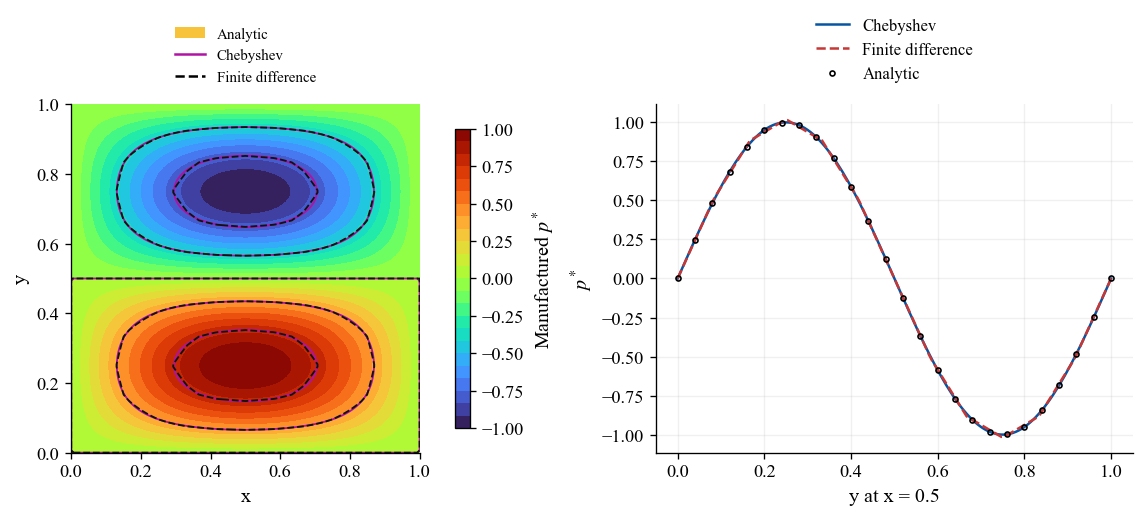

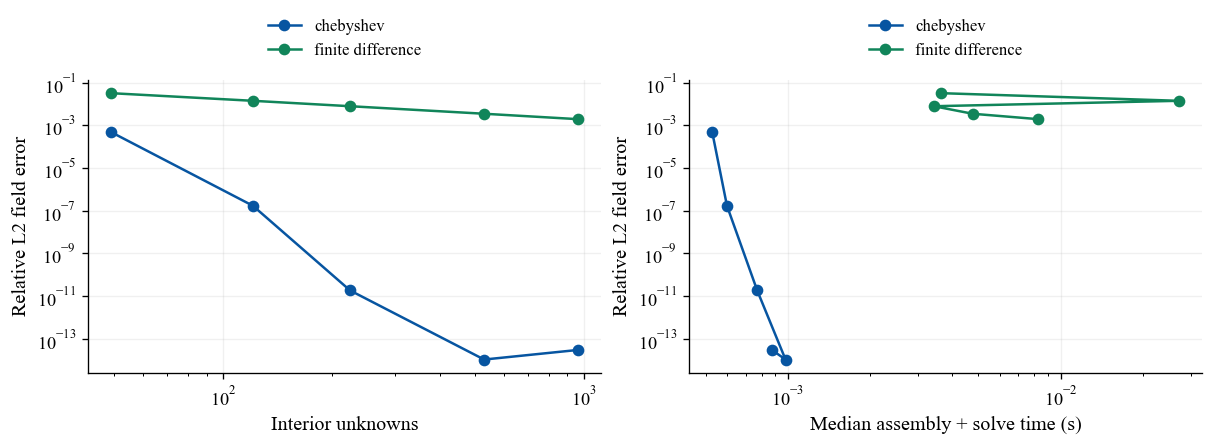

In [6]:
# Same levels and physical extent; no per-method colour rescaling.
N_FIELD = 12
query = np.linspace(0, 1, 151)
yy, xx = np.meshgrid(query, query, indexing="ij")
reference = exact_pressure(xx, yy)
levels = [-0.8, -0.4, 0.0, 0.4, 0.8]
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
filled = axes[0].contourf(xx, yy, reference, levels=np.linspace(-1, 1, 25), cmap="turbo")
fig.colorbar(filled, ax=axes[0], label=r"Manufactured $p^*$", shrink=0.86)
for method, color, style in [("chebyshev", "#b012a5", "solid"), ("finite_difference", "#111111", "dashed")]:
    sol = pressure_solutions.get((method, N_FIELD)) or poisson_square(N_FIELD, method)
    evaluated = interpolate_field(sol["x"], sol["p"], query, method)
    axes[0].contour(xx, yy, evaluated, levels=levels, colors=color, linestyles=style, linewidths=1.1)
    axes[1].plot(query, evaluated[:, 75], color=COLORS[0] if method=="chebyshev" else COLORS[2],
                 ls="-" if method=="chebyshev" else "--", label=method.replace("_", " ").capitalize())
axes[0].set(xlabel="x", ylabel="y", aspect="equal")
handles = [Patch(facecolor=plt.get_cmap("turbo")(0.65), label="Analytic"),
           Line2D([], [], color="#b012a5", label="Chebyshev"),
           Line2D([], [], color="k", ls="--", label="Finite difference")]
axes[0].legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False, fontsize=9)
axes[1].plot(query[::6], reference[::6, 75], "ko", ms=3, fillstyle="none", label="Analytic")
axes[1].set(xlabel="y at x = 0.5", ylabel=r"$p^*$")
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)
axes[1].grid(alpha=0.18)
save_figure(fig, "pressure_poisson_fields")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for color, (name, group) in zip(COLORS, table_p.groupby("method", sort=False)):
    label = name.replace("_", " ")
    axes[0].loglog(group.unknowns, group.relative_L2, "o-", color=color, label=label)
    axes[1].loglog(group.assembly_solve_median_s, group.relative_L2, "o-", color=color, label=label)
axes[0].set(xlabel="Interior unknowns", ylabel="Relative L2 field error")
axes[1].set(xlabel="Median assembly + solve time (s)", ylabel="Relative L2 field error")
for ax in axes:
    ax.grid(alpha=0.18)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)
save_figure(fig, "poisson_accuracy_cost")

## 4. Algorithm trace and boundary-condition check

**Chebyshev Poisson algorithm:** choose $N$ → construct $(x,D)$ → form $D^2$ →
restrict to interior rows/columns → assemble $F$ from the physical source →
solve $AP+PA^T=F$ → insert prescribed boundary values → evaluate residual and off-grid error.

For a pressure correction $p'$ in an incompressible solver, a simplified projection has
$\nabla^2p'=(\rho/\Delta t)\nabla\cdot\mathbf{u}^{\star}$ and
$\mathbf{u}^{new}=\mathbf{u}^{\star}-(\Delta t/\rho)\nabla p'$.
Here $\mathbf{u}^{\star}$ is the predicted velocity, $\rho$ density and $\Delta t$ the time step.
The actual boundary conditions and discrete gradient/divergence must be derived together
from the wall and face-flux equations. SIMPLE can instead use a variable momentum-based coefficient.
Replacing a pressure matrix by this standalone **Dirichlet** example is not a complete cavity implementation.

**Checkpoint P:** compare a coarse FD row with a Chebyshev row. Can both have a tiny
equation residual but different field errors? At a fixed error tolerance, which row would you choose?

## 5. Discontinuous Galerkin: local polynomials communicate through fluxes

Solve $q_t+a q_x=0$ on $0\leq x<1$ with periodic boundaries.
The exact solution is $q(x,t)=q_0((x-at)\bmod1)$.
Divide the interval into $K$ cells of width $h=1/K$. On cell $e$, use
$$q_h(x,t)=\sum_{n=0}^{p}c_{e,n}(t)P_n(\xi),\qquad \xi=2(x-x_{e,L})/h-1.$$
$P_n$ is the degree-$n$ Legendre polynomial; $p$ is polynomial degree, not pressure.
There are $K(p+1)$ unknown coefficients. Different cells have distinct endpoint traces.

Multiply by $P_m$, integrate by parts within a cell and replace the interface flux by
$$\widehat f=\frac a2(q^-+q^+)-\frac{\alpha|a|}{2}(q^+-q^-).$$
$q^-$ and $q^+$ are the left and right traces at the same interface.
$\alpha=0$ gives a central flux; $\alpha=1$ gives upwind flux for either sign of $a$.

Legendre orthogonality makes the cell mass matrix diagonal: $M_{mm}=h/(2m+1)$.
The coefficient update is
$$\dot c_{e,m}=\frac{2m+1}{h}\left[a\sum_n S_{mn}c_{e,n}-\widehat f_R+(-1)^m\widehat f_L\right],$$
where $S_{mn}=\int_{-1}^{1}P'_mP_n\,d\xi$ equals 2 when $m>n$ and $m-n$ is odd, and zero otherwise.
The same interface flux leaves one cell and enters its neighbour: this is the conservation mechanism.

**Connection to Week 1.2:** at $p=0$, the volume term vanishes and
$\dot c_{e,0}=-(\widehat f_R-\widehat f_L)/h$. This is the conservative finite-volume
update for a cell average. DG extends that idea with more coefficients inside each cell.

In [7]:
def initial_wave(x, kind="smooth"):
    """Periodic data on a unit interval; smooth, localized, or discontinuous."""
    x = np.asarray(x) % 1.0
    if kind == "smooth":
        return 0.6 * np.sin(2 * np.pi * x) + 0.2 * np.cos(6 * np.pi * x)
    if kind == "localized":
        return np.exp(-60 * np.sin(np.pi * (x - 0.35))**2)
    if kind == "step":
        return ((x >= 0.25) & (x < 0.55)).astype(float)
    raise ValueError("kind must be smooth, localized or step")


def dg_operators(elements=16, degree=3, speed=1.0, dissipation=1.0):
    """Modal Legendre DG on equal periodic cells; 0=central flux, 1=upwind."""
    if not isinstance(elements, (int, np.integer)) or elements < 2:
        raise ValueError("elements must be an integer >= 2")
    if not isinstance(degree, (int, np.integer)) or not 0 <= degree <= 8:
        raise ValueError("degree must be an integer from 0 to 8 for this lab")
    if not np.isfinite(speed) or speed == 0 or not 0 <= dissipation <= 1:
        raise ValueError("Use finite nonzero speed and dissipation in [0,1]")
    h = 1.0 / elements
    k = np.arange(degree + 1)
    # S[m,n] = integral P'_m P_n: exactly 2 for m>n with odd m-n.
    s = 2.0 * ((k[:, None] > k[None, :]) & ((k[:, None] - k[None, :]) % 2 == 1))
    return dict(elements=elements, degree=degree, speed=float(speed),
                dissipation=float(dissipation), h=h, s=s, left=(-1.0)**k,
                inverse_mass=(2 * k + 1) / h)


def dg_project(ops, kind="smooth"):
    """L2 projection using Gauss integration, split at step discontinuities."""
    e, p, h = ops["elements"], ops["degree"], ops["h"]
    z, w = leggauss(max(32, 2 * p + 4))
    coefficients = np.zeros((e, p + 1))
    for cell in range(e):
        lo, hi = cell * h, (cell + 1) * h
        cuts = [lo] + ([c for c in (0.25, 0.55) if lo < c < hi] if kind == "step" else []) + [hi]
        for a, b in zip(cuts[:-1], cuts[1:]):
            x = (a + b) / 2 + (b - a) * z / 2
            xi = 2 * (x - lo) / h - 1
            coefficients[cell] += ((b - a) / 2) * (w * initial_wave(x, kind)) @ legvander(xi, p)
    return coefficients * ops["inverse_mass"][None, :]


def dg_rhs(coefficients, ops):
    """Weak-form volume derivative plus a single conservative interface flux."""
    a, alpha = ops["speed"], ops["dissipation"]
    right_trace = coefficients.sum(axis=1)
    left_trace = coefficients @ ops["left"]
    neighbour = np.roll(left_trace, -1)
    flux_right = 0.5 * a * (right_trace + neighbour) - 0.5 * alpha * abs(a) * (neighbour - right_trace)
    flux_left = np.roll(flux_right, 1)
    volume = a * (coefficients @ ops["s"].T)
    return (volume - flux_right[:, None] + flux_left[:, None] * ops["left"]) * ops["inverse_mass"]


def dg_values(coefficients, ops, x):
    """Evaluate each cell's polynomial, with the right-cell trace at interfaces."""
    x = np.asarray(x) % 1.0
    indices = np.minimum((x / ops["h"]).astype(int), ops["elements"] - 1)
    xi = 2 * (x / ops["h"] - indices) - 1
    return np.sum(coefficients[indices] * legvander(xi, ops["degree"]), axis=-1)


def dg_diagnostics(coefficients, ops):
    mass = ops["h"] * coefficients[:, 0].sum()
    energy = 0.5 * np.sum(coefficients**2 / ops["inverse_mass"][None, :])
    return float(mass), float(energy)

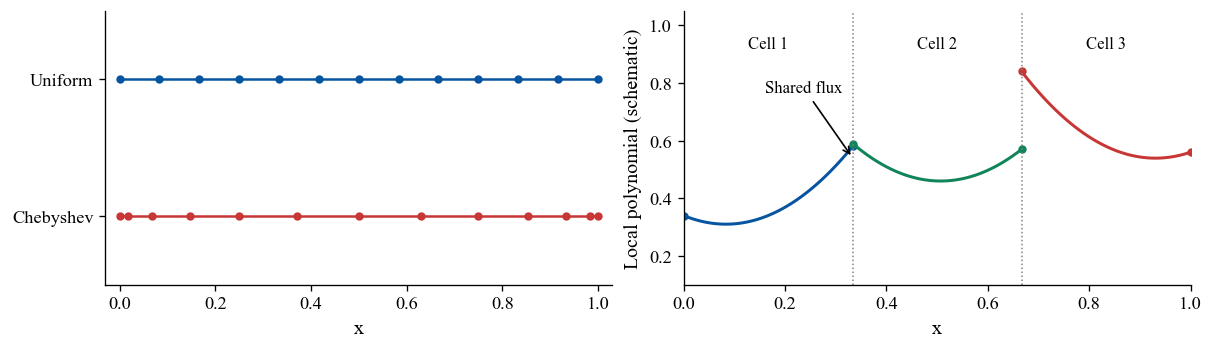

In [8]:
# Schematic only: global nodes versus independently represented DG cells.
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8), layout="constrained")
nodes, _ = chebyshev_grid(12)
for yrow, nodeset, label, color in [(1.0, np.linspace(0,1,13), "Uniform nodes", COLORS[0]),
                                   (0.0, nodes, "Chebyshev nodes", COLORS[2])]:
    axes[0].plot(nodeset, np.full_like(nodeset,yrow), "o-", color=color, ms=4)
axes[0].set(xlim=(-0.03,1.03), ylim=(-0.5,1.5), xlabel="x", yticks=[0,1],
            yticklabels=["Chebyshev", "Uniform"])
for e in range(3):
    xi = np.linspace(-1,1,60)
    local_x = (e+(xi+1)/2)/3
    values = (0.38+0.12*e) + (0.12-0.13*e)*xi + 0.12*(xi**2-1/3)
    axes[1].plot(local_x, values, color=COLORS[e], lw=1.8)
    axes[1].plot([local_x[0],local_x[-1]], [values[0],values[-1]], "o", color=COLORS[e], ms=4)
    axes[1].text((e+0.5)/3, 0.92, f"Cell {e+1}", ha="center", fontsize=10)
for xface in [1/3,2/3]:
    axes[1].axvline(xface, color="0.5", ls=":", lw=0.9)
axes[1].annotate("Shared flux", xy=(1/3,0.54), xytext=(0.16,0.77),
                 arrowprops={"arrowstyle":"->", "color":"black"}, fontsize=10)
axes[1].set(xlim=(0,1), ylim=(0.1,1.05), xlabel="x", ylabel="Local polynomial (schematic)")
save_figure(fig, "spatial_representation_schematic")

## 6. Projection, time stepping and measurable invariants

Initialize coefficients by the $L^2$ projection
$c_{e,m}(0)=(2m+1)h^{-1}\int_{I_e}q_0(x)P_m(\xi(x))\,dx$.
Gauss quadrature evaluates smooth integrals; the step target is split at its discontinuities
before integration. Sampling only the cell centre would not initialize higher DG modes correctly.

The spatial operator is $L(c)$. SSPRK3 advances it using
$$c^{(1)}=c^n+\Delta tL(c^n),\qquad
c^{(2)}=\tfrac34c^n+\tfrac14[c^{(1)}+\Delta tL(c^{(1)})],$$
$$c^{n+1}=\tfrac13c^n+\tfrac23[c^{(2)}+\Delta tL(c^{(2)})].$$
We choose $\Delta t\leq C h/[|a|(2p+1)]$, shorten it to land exactly on the final time,
and use $C=0.12$ by default. This is a conservative tested lab setting, **not a universal CFL bound**.

Track mass $\mathcal M=h\sum_e c_{e,0}$ and energy
$E=\frac12\sum_{e,m}h c_{e,m}^2/(2m+1)$.
For this periodic linear problem the semidiscrete identity is
$dE/dt=-\frac12\alpha|a|\sum_{interfaces}(q^+-q^-)^2$.
Central flux has no semidiscrete energy dissipation, but time integration still changes energy.
Upwind dissipation suppresses unresolved modes. Neither flux makes an unlimited high-order
solution monotone at a discontinuity; SSPRK3 alone is not a shock limiter.

In [9]:
def solve_dg(elements=16, degree=3, speed=1.0, dissipation=1.0,
             kind="smooth", final_time=0.35, cfl=0.12):
    """SSPRK3 with dt <= cfl*h/(|a|*(2p+1)); cfl is a lab control, not a theorem.

    Return a finite-interval transport experiment, never a cavity flow solution.
    A work cap protects interactive Run All from accidental huge settings.
    """
    ops = dg_operators(elements, degree, speed, dissipation)
    if not np.isfinite(final_time) or final_time <= 0 or not np.isfinite(cfl) or cfl <= 0:
        raise ValueError("final_time and cfl must be finite and positive")
    steps = int(np.ceil(final_time * abs(speed) * (2 * degree + 1) / (cfl * ops["h"])))
    if steps > 100000:
        raise ValueError("More than 100000 steps: reduce the interactive workload")
    dt = final_time / steps
    started = perf_counter()
    q = dg_project(ops, kind)
    mass0, energy0 = dg_diagnostics(q, ops)
    history = [(0.0, mass0, energy0)]
    for step in range(steps):
        q1 = q + dt * dg_rhs(q, ops)
        q2 = 0.75 * q + 0.25 * (q1 + dt * dg_rhs(q1, ops))
        q = q / 3 + 2 / 3 * (q2 + dt * dg_rhs(q2, ops))
        if not np.isfinite(q).all() or np.max(np.abs(q)) > 1e8:
            raise RuntimeError("Unstable DG trajectory: decrease CFL; preserve the failed setting")
        if (step + 1) % max(1, steps // 80) == 0 or step + 1 == steps:
            history.append(((step + 1) * dt, *dg_diagnostics(q, ops)))
    elapsed = perf_counter() - started
    x = (np.arange(4096) + 0.5) / 4096
    exact = initial_wave(x - speed * final_time, kind)
    predicted = dg_values(q, ops, x)
    error = predicted - exact
    return dict(ops=ops, coefficients=q, history=np.asarray(history),
                x=x, exact=exact, predicted=predicted, kind=kind, dt=dt,
                steps=steps, rhs_calls=3 * steps, dofs=elements * (degree + 1),
                seconds=elapsed, final_time=final_time, cfl=cfl,
                mass_drift=float(dg_diagnostics(q, ops)[0] - mass0),
                relative_l2=float(np.linalg.norm(error) / np.linalg.norm(exact)),
                max_error=float(np.max(np.abs(error))))

,K,p,alpha,dofs,dt,rhs_calls,seconds,relative_L2,max_error,mass_drift
Table D: same number of coefficients,,,,,,,,,,
0,64,0,1.0,64,0.001872,561,0.151000,0.628960,0.635703,-5.134781e-16
1,32,1,1.0,64,0.001250,840,0.280975,0.198896,0.208899,-8.187895e-16
2,16,3,1.0,64,0.001070,981,0.307172,0.035778,0.039710,-8.604228e-16
3,8,7,1.0,64,0.001000,1050,0.139318,0.007085,0.008101,-1.026956e-15


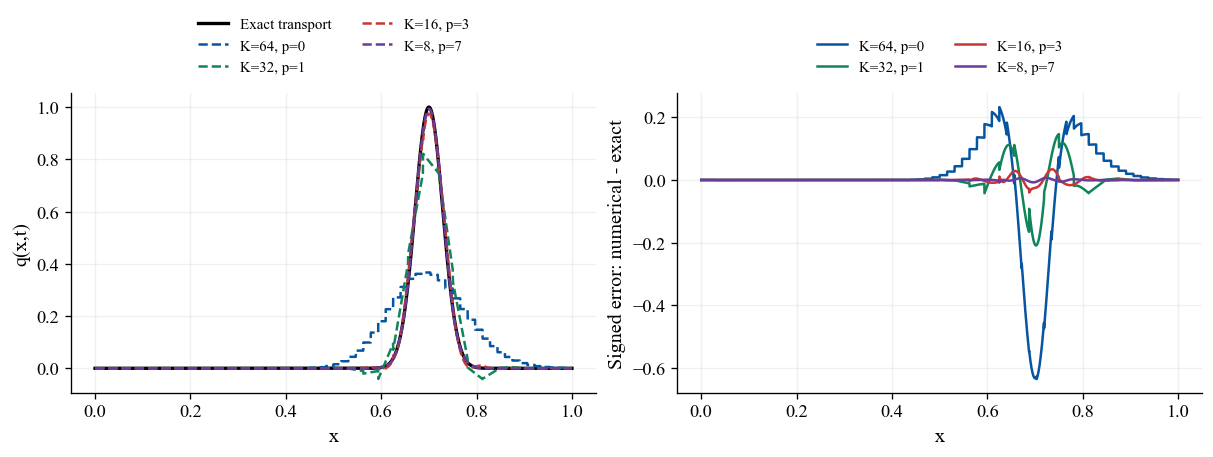

In [10]:
# Experiment D controls. Equal 64 coefficients, different h/p allocations.
DG_CASES = [(64, 0), (32, 1), (16, 3), (8, 7)]
TARGET = "localized"  # "smooth", "localized", or "step"
SPEED = 1.0
FINAL_TIME = 0.35
CFL = 0.12
ALPHA = 1.0
dg_solutions = [solve_dg(k, p, SPEED, ALPHA, TARGET, FINAL_TIME, CFL) for k, p in DG_CASES]
def dg_row(sol):
    return {"K":sol["ops"]["elements"], "p":sol["ops"]["degree"],
            "alpha":sol["ops"]["dissipation"], "dofs":sol["dofs"],
            "dt":sol["dt"], "rhs_calls":sol["rhs_calls"], "seconds":sol["seconds"],
            "relative_L2":sol["relative_l2"], "max_error":sol["max_error"], "mass_drift":sol["mass_drift"]}
table_d = pd.DataFrame([dg_row(s) for s in dg_solutions])
display(table_d.rename_axis("Table D: same number of coefficients"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
axes[0].plot(dg_solutions[0]["x"], dg_solutions[0]["exact"], "k-", lw=2, label="Exact transport")
for color, sol in zip(COLORS, dg_solutions):
    label = f"K={sol['ops']['elements']}, p={sol['ops']['degree']}"
    axes[0].plot(sol["x"], sol["predicted"], color=color, ls="--", label=label)
    axes[1].plot(sol["x"], sol["predicted"]-sol["exact"], color=color, label=label)
axes[0].set(xlabel="x", ylabel="q(x,t)")
axes[1].set(xlabel="x", ylabel="Signed error: numerical - exact")
for ax in axes:
    ax.grid(alpha=0.18)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=False, fontsize=9)
save_figure(fig, "dg_transport_equal_dofs")

## 7. A discontinuity exposes the flux tradeoff

Use a square pulse equal to one on $[0.25,0.55)$ and zero elsewhere, transported by the same PDE.
The exact mass is 0.3. The field is not a gas-dynamic shock: there is no nonlinear wave speed,
equation of state or Mach number. It isolates numerical transport near a sharp front.

Both calculations below use the same $K$, $p$, time step and projected initial condition.
Do not clip negative values or overshoots: their amplitude is part of the result.

,K,p,alpha,dofs,dt,rhs_calls,seconds,relative_L2,max_error,mass_drift,minimum,maximum
Table F: flux and extrema,,,,,,,,,,,,
0,24,3,0.0,96,0.000714,1470,0.277975,0.183023,0.609637,-5.329071e-15,-0.271074,1.143740
1,24,3,1.0,96,0.000714,1470,0.329185,0.135853,0.525103,-5.329071e-15,-0.097554,1.131077


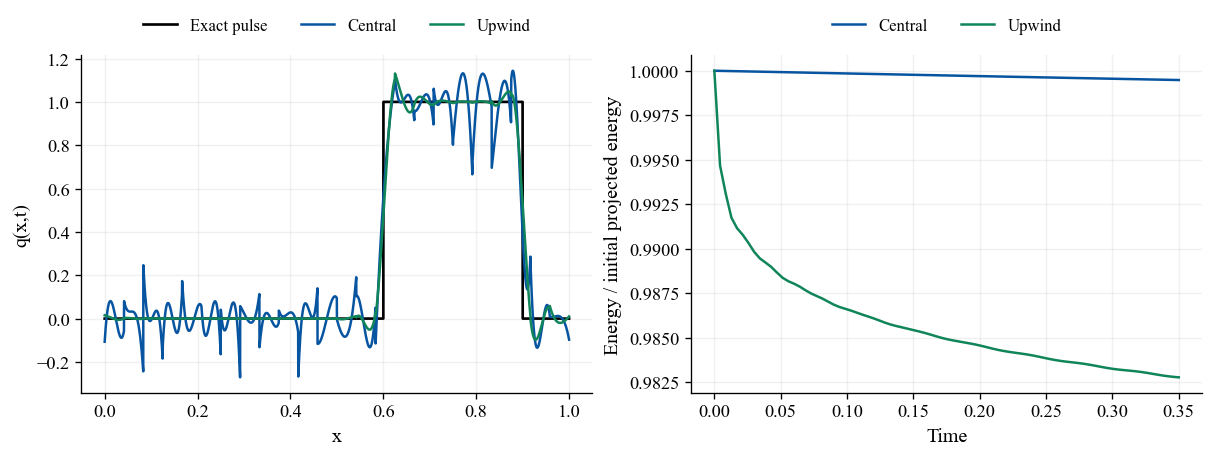

In [11]:
# Experiment F controls. A change to the target is local to this comparison.
FLUX_K, FLUX_P = 24, 3
flux_solutions = [solve_dg(FLUX_K, FLUX_P, speed=SPEED, dissipation=alpha,
                          kind="step", final_time=FINAL_TIME, cfl=CFL) for alpha in (0.0, 1.0)]
table_f = pd.DataFrame([{**dg_row(s), "minimum":s["predicted"].min(), "maximum":s["predicted"].max()}
                        for s in flux_solutions])
display(table_f.rename_axis("Table F: flux and extrema"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")
axes[0].plot(flux_solutions[0]["x"], flux_solutions[0]["exact"], "k-", lw=1.6, label="Exact pulse")
for color, label, sol in zip(COLORS, ["Central", "Upwind"], flux_solutions):
    axes[0].plot(sol["x"], sol["predicted"], color=color, label=label)
    history = sol["history"]
    axes[1].plot(history[:,0], history[:,2]/history[0,2], color=color, label=label)
axes[0].set(xlabel="x", ylabel="q(x,t)")
axes[1].set(xlabel="Time", ylabel="Energy / initial projected energy")
for ax in axes:
    ax.grid(alpha=0.18)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False, ncol=3)
save_figure(fig, "dg_flux_pulse_energy")

## 8. Separate time error from spatial error

Keep the DG space and smooth target fixed. Compare $C$, $C/2$ and $C/4$.
The exact final time is unchanged. An observed factor near 8 between successive
coefficient differences is consistent with third-order time stepping when temporal error dominates.
Total error against the exact PDE can plateau because spatial error remains.
Integer step counts make the actual step ratios only approximately two; Table T reports the actual
values. Interpret the observed order as an approximate diagnostic of this nominal CFL-halving study.

In [12]:
# Experiment T controls. The fixed space is deliberately accurate for the smooth wave.
TIME_K, TIME_P = 8, 5
time_solutions = [solve_dg(TIME_K, TIME_P, kind="smooth", final_time=0.35, cfl=c)
                  for c in (0.12, 0.06, 0.03)]
table_t = pd.DataFrame([{**dg_row(s), "CFL":s["cfl"]} for s in time_solutions])
display(table_t.rename_axis("Table T: time refinement"))
gap_1 = np.linalg.norm(time_solutions[0]["coefficients"]-time_solutions[1]["coefficients"])
gap_2 = np.linalg.norm(time_solutions[1]["coefficients"]-time_solutions[2]["coefficients"])
time_ratio = gap_1/gap_2
print("Successive coefficient-difference ratio:", time_ratio)
print("Observed temporal order from differences:", np.log2(time_ratio))

,K,p,alpha,dofs,dt,rhs_calls,seconds,relative_L2,max_error,mass_drift,CFL
Table T: time refinement,,,,,,,,,,,
0,8,5,1.0,48,0.001362,771,0.191073,0.000033,0.000092,-1.387779e-16,0.12
1,8,5,1.0,48,0.000681,1542,0.377886,0.000033,0.000093,-4.163336e-17,0.06
2,8,5,1.0,48,0.000341,3081,0.146836,0.000033,0.000093,2.498002e-16,0.03


Successive coefficient-difference ratio: 8.00336322674824
Observed temporal order from differences: 3.0006063863643853


## 9. h-refinement, p-refinement and an honest accuracy decision

$h$-refinement increases the number of cells $K$; $p$-refinement increases polynomial degree
inside a fixed cell partition. Equal unknowns do not imply equal time steps or work.
Table H changes $K$ at fixed degree; Table D held coefficient count fixed.
These are different experimental questions.

For the smooth periodic target, measure error at 4096 fixed midpoint locations in $[0,1)$.
Relative $L^2$ means the sampled Euclidean error norm divided by the exact sampled norm.
This dense evaluation is distinct from the Gauss quadrature used for coefficient projection.

,K,p,alpha,dofs,dt,rhs_calls,seconds,relative_L2,max_error,mass_drift,observed_order
Table H: fixed degree p=2,,,,,,,,,,,
0,8,2,1.0,24,0.001496,702,0.054976,0.024019,0.027519,1.942890e-16,NaN
1,16,2,1.0,48,0.000749,1401,0.088497,0.002582,0.005403,2.216109e-16,3.217672
2,32,2,1.0,96,0.000375,2802,0.256960,0.000317,0.000717,1.344411e-17,3.023739


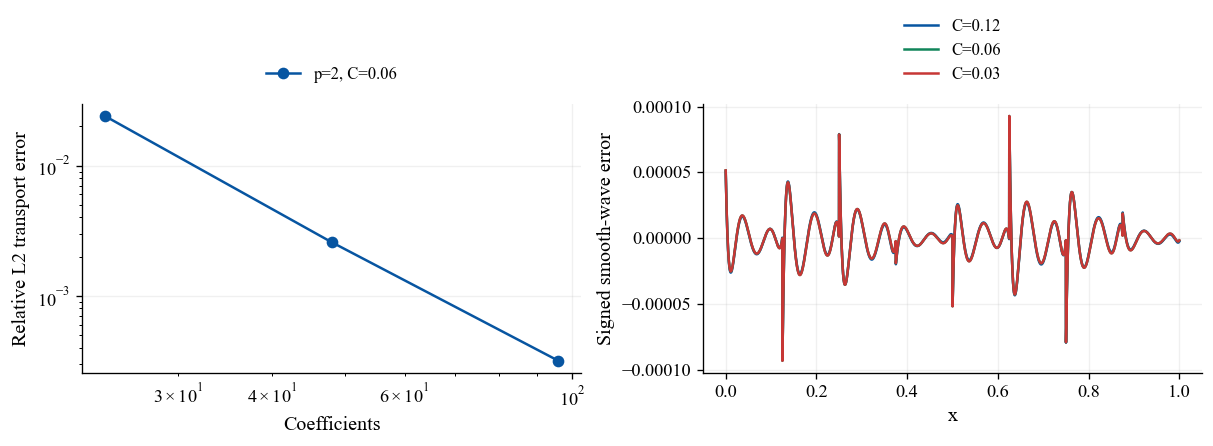

In [13]:
# Experiment H controls. Use a smaller CFL to keep temporal error below the spatial trend.
h_solutions = [solve_dg(k, 2, kind="smooth", final_time=0.35, cfl=0.06) for k in (8, 16, 32)]
table_h = pd.DataFrame([dg_row(s) for s in h_solutions])
table_h["observed_order"] = [np.nan] + [np.log2(h_solutions[i-1]["relative_l2"]/h_solutions[i]["relative_l2"])
                                           for i in range(1, len(h_solutions))]
display(table_h.rename_axis("Table H: fixed degree p=2"))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
axes[0].loglog(table_h["dofs"], table_h["relative_L2"], "o-", color=COLORS[0], label="p=2, C=0.06")
axes[0].set(xlabel="Coefficients", ylabel="Relative L2 transport error")
for color, sol in zip(COLORS, time_solutions):
    axes[1].plot(sol["x"], sol["predicted"]-sol["exact"], color=color, label=f"C={sol['cfl']}")
axes[1].set(xlabel="x", ylabel="Signed smooth-wave error")
for ax in axes:
    ax.grid(alpha=0.18)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), frameon=False)
save_figure(fig, "dg_refinement_time")

## 10. Solve the actual lid-driven cavity

The next cells solve the **steady, two-dimensional incompressible Navier–Stokes equations**,
including pressure. They recompute the flow; Ghia's values are used only afterwards for comparison.
The unit square has $L=1$, density $\rho=1$, open-edge lid speed $U_{lid}=1$ in the $+x$ direction,
and kinematic viscosity $\nu=1/Re$. The other walls are stationary and impermeable.
The two lid-corner values are set to zero, following the stationary side walls; no smoothing is hidden.

$$u u_x+v u_y=-p_x+Re^{-1}(u_{xx}+u_{yy}),$$
$$u v_x+v v_y=-p_y+Re^{-1}(v_{xx}+v_{yy}),\qquad u_x+v_y=0.$$

Here $u,v$ are velocity components, $x,y$ are position, $p$ is pressure divided by
$\rho U_{lid}^2$, and subscripts indicate derivatives. Pressure is determined up to a constant;
we impose $p(1/2,1/2)=0$. There is no imposed zero-pressure wall condition.
The standard cavity has neither a Mach number nor a Knudsen number in this incompressible model.

### 10.1 Spatial operators and pressure–velocity coupling

Velocity uses the same $N+1$ Chebyshev points introduced above. Its boundary values are prescribed;
the two interior velocity arrays each have $(N-1)^2$ unknowns. Pressure uses a degree-$N-2$
polynomial through the $N-1$ interior points per direction, so its derivative matrix is built
from **those nodes**, rather than slicing the velocity derivative matrix.
This mixed approximation reduces the spurious pressure modes of an equal-degree construction.

Let $z=(u_I,v_I,p_I)$ collect the interior unknowns, and let $F(z)$ contain both steady momentum
residuals and the discrete divergence. One redundant continuity row is replaced by the pressure gauge.
The omitted continuity equation is still checked when deciding whether the calculation converged.

$$J(z_k)\,\delta z=-F(z_k),\qquad z_{k+1}=z_k+\lambda\delta z,\qquad 0<\lambda\leq1.$$

$J$ is the exact Jacobian of the discrete equations; $k$ counts Newton iterations and $\lambda$
is a backtracking damping factor. Each iteration solves velocity and pressure together.
This differs from SIMPLE/PISO/PIMPLE's correction loops, but solves the same steady physical equations.
**An iteration is not a physical time step.** Starting the algebraic solve with zero interior values
does not produce a time-resolved startup history.

The dense implementation deliberately supports even $8\leq N\leq32$: at $N=32$ it has 2883
coupled unknowns and needs memory for dense matrices. That keeps the code inspectable on a normal
CPU. Larger research calculations need scalable linear algebra, not a GPU requirement for this lab.

**Read the solver in this order:** `cavity_operators` → `cavity_residual` → `cavity_jacobian` →
`solve_spectral_cavity`. The remaining routines differentiate pressure and evaluate saved polynomials.

In [14]:
def nodal_derivative(nodes):
    """Derivative matrix for the actual supplied nodes, including pressure nodes."""
    difference = nodes[:, None] - nodes[None, :]
    np.fill_diagonal(difference, 1.0)
    weights = 1.0 / np.prod(difference, axis=1)
    derivative = weights[None, :] / weights[:, None] / difference
    np.fill_diagonal(derivative, 0.0)
    np.fill_diagonal(derivative, -derivative.sum(axis=1))
    return derivative


def cavity_operators(n=24, reynolds=100.0, lid="standard"):
    """Dense teaching operators, bounded to at most 2883 coupled unknowns.

    Even N includes the centre node for an unambiguous pressure gauge.
    A higher resolution should use a scalable implementation, not this dense lab.
    """
    if not isinstance(n, (int, np.integer)) or n % 2 or not 8 <= n <= 32:
        raise ValueError("Use even N from 8 to 32 in this CPU teaching implementation")
    if not np.isfinite(reynolds) or reynolds <= 0:
        raise ValueError("Re must be finite and positive")
    if lid not in ("standard", "smooth", "stationary"):
        raise ValueError("lid must be standard, smooth or stationary")
    x, d = chebyshev_grid(n)
    d2, m = d @ d, n - 1
    interior = np.s_[1:-1, 1:-1]
    eye_m = np.eye(m)
    dx = np.kron(eye_m, d[interior])
    dy = np.kron(d[interior], eye_m)
    lap = np.kron(eye_m, d2[interior]) + np.kron(d2[interior], eye_m)
    dp = nodal_derivative(x[1:-1])
    gx, gy = np.kron(eye_m, dp), np.kron(dp, eye_m)
    boundary_u = np.zeros((n + 1, n + 1))
    if lid == "standard":
        boundary_u[-1, 1:-1] = 1.0
    elif lid == "smooth":
        boundary_u[-1, :] = 16 * x**2 * (1-x)**2
    # Both corner velocities are zero; the open top edge moves in +x.
    return dict(n=n, m=m, size=m*m, x=x, d=d, d2=d2, dx=dx, dy=dy,
                lap=lap, gx=gx, gy=gy, reynolds=float(reynolds), lid=lid,
                boundary_u=boundary_u, gauge=(m*m)//2,
                boundary_ux=(boundary_u @ d.T)[interior].ravel(),
                boundary_uy=(d @ boundary_u)[interior].ravel(),
                boundary_lap=(d2 @ boundary_u + boundary_u @ d2.T)[interior].ravel())


def cavity_residual(state, ops, forcing=None):
    """All steady momentum equations plus continuity; one redundant row sets p_c=0."""
    u, v, p = np.split(state, 3)
    dx, dy, lap = ops["dx"], ops["dy"], ops["lap"]
    ux, uy = dx @ u + ops["boundary_ux"], dy @ u + ops["boundary_uy"]
    vx, vy = dx @ v, dy @ v
    ru = -(lap @ u + ops["boundary_lap"]) / ops["reynolds"] + u*ux + v*uy + ops["gx"] @ p
    rv = -(lap @ v) / ops["reynolds"] + u*vx + v*vy + ops["gy"] @ p
    if forcing is not None:
        ru, rv = ru - forcing[0], rv - forcing[1]
    continuity = dx @ u + dy @ v
    continuity[ops["gauge"]] = p[ops["gauge"]]
    return np.concatenate((ru, rv, continuity))


def cavity_jacobian(state, ops):
    """Exact derivative of the discrete advective-form residual for Newton's method."""
    u, v, _ = np.split(state, 3)
    dx, dy = ops["dx"], ops["dy"]
    ux, uy = dx @ u + ops["boundary_ux"], dy @ u + ops["boundary_uy"]
    vx, vy = dx @ v, dy @ v
    a = -ops["lap"] / ops["reynolds"] + u[:, None]*dx + v[:, None]*dy
    bx, by = dx.copy(), dy.copy()
    bx[ops["gauge"], :] = 0.0
    by[ops["gauge"], :] = 0.0
    pp = np.zeros_like(dx)
    pp[ops["gauge"], ops["gauge"]] = 1.0
    return np.block([[a+np.diag(ux), np.diag(uy), ops["gx"]],
                     [np.diag(vx), a+np.diag(vy), ops["gy"]],
                     [bx, by, pp]])


def cavity_sample(result, field, x_query, y_query):
    """Evaluate the saved polynomial; arrays and results use field[y,x].

    The pressure polynomial has its own N-1 nodes, not the velocity's N+1 nodes.
    Evaluation at the walls is a polynomial continuation, not pressure wall data.
    """
    nodes = result["x"][1:-1] if field == "p" else result["x"]
    identity = np.eye(len(nodes))
    interpolation_x = BarycentricInterpolator(nodes, identity, axis=0)(np.atleast_1d(x_query))
    interpolation_y = BarycentricInterpolator(nodes, identity, axis=0)(np.atleast_1d(y_query))
    return interpolation_y @ result[field] @ interpolation_x.T


def solve_spectral_cavity(n=24, reynolds=100.0, lid="standard", tolerance=1e-9,
                          max_iterations=25, forcing=None):
    """Solve the steady incompressible cavity from scratch with damped Newton.

    There is no physical time march and no fitted Ghia data. A converged flag
    certifies the algebraic criterion only. Re=100/400 are the classroom cases;
    other Re require their own resolution/convergence evidence.
    forcing is reserved for manufactured verification, absent in the driven cavity.
    """
    if not np.isfinite(tolerance) or tolerance <= 0 or max_iterations < 1:
        raise ValueError("Use positive tolerance and iteration budget")
    started = perf_counter()
    ops = cavity_operators(n, reynolds, lid)
    state = np.zeros(3 * ops["size"])
    history, reason = [], "iteration budget reached"
    for iteration in range(max_iterations + 1):
        residual = cavity_residual(state, ops, forcing)
        norm = float(np.max(np.abs(residual)))
        u, v, _ = np.split(state, 3)
        # Include the continuity equation removed to impose the gauge.
        divergence = float(np.max(np.abs(ops["dx"] @ u + ops["dy"] @ v)))
        history.append([iteration, norm, divergence, 0.0])
        if not np.isfinite(norm):
            reason = "nonfinite residual"
            break
        if max(norm, divergence) <= tolerance:
            reason = "converged discrete steady equations"
            break
        if iteration == max_iterations:
            break
        delta = solve(cavity_jacobian(state, ops), -residual, assume_a="gen", check_finite=False)
        damping, accepted = 1.0, False
        for _ in range(15):
            trial = state + damping * delta
            trial_norm = np.max(np.abs(cavity_residual(trial, ops, forcing)))
            if np.isfinite(trial_norm) and trial_norm <= (1 - 1e-4*damping) * norm:
                state, accepted = trial, True
                break
            damping *= 0.5
        history[-1][3] = damping if accepted else 0.0
        if not accepted:
            reason = "line search failed; no convergence claimed"
            break
    u, v, p = np.split(state, 3)
    uf, vf = ops["boundary_u"].copy(), np.zeros_like(ops["boundary_u"])
    uf[1:-1, 1:-1], vf[1:-1, 1:-1] = u.reshape(ops["m"], ops["m"]), v.reshape(ops["m"], ops["m"])
    result = dict(n=n, reynolds=float(reynolds), lid=lid, x=ops["x"],
                  u=uf, v=vf, p=p.reshape(ops["m"], ops["m"]),
                  omega=vf @ ops["d"].T - ops["d"] @ uf,
                  divergence=uf @ ops["d"].T + ops["d"] @ vf,
                  history=np.asarray(history), iterations=len(history)-1,
                  residual_max=history[-1][1], divergence_nodes_max=history[-1][2],
                  converged=(reason == "converged discrete steady equations"), stop_reason=reason,
                  state=state, tolerance=float(tolerance),
                  solve_seconds=perf_counter()-started)
    # A fixed off-grid core, disclosed separately from the singular corner zones.
    query = np.linspace(0.05, 0.95, 101)
    core_div = cavity_sample(result, "divergence", query, query)
    result["divergence_core_rms"] = float(np.sqrt(np.mean(core_div**2)))
    result["divergence_core_max"] = float(np.max(np.abs(core_div)))
    return result

### 10.2 Run and qualify two Reynolds numbers

Start with Re=100, then observe Re=400. The supplied Run All uses N=16,24,32 for each.
For a shorter first pass set `CAVITY_REYNOLDS = [100]`; the tables and plots adapt.
Do not tighten a residual tolerance and call that mesh refinement.

**Table C** reports actual solve time, Newton iterations, momentum/gauge residual, all interior-node
continuity equations, and an independent off-grid continuity diagnostic.
The latter is RMS of the differentiated velocity polynomial on 101×101 fixed locations in
$[0.05,0.95]^2$. It is **not** a full-domain norm and excludes the immediate corner zones.
A collocation residual can be tiny while this spatial defect remains visible.

Ghia's 17 samples per component are embedded from the repository's original table, with their
reported precision and provenance. In Re=400 the previously flagged printed $v$ value at x=0.9063
is retained and marked; both all-sample and screened scores are reported. No replacement value is invented.
RMS errors are in lid-speed units. Relative L2 uses one whole-profile reference norm, never division
by a pointwise velocity near a zero crossing. Ghia supplies velocity profiles, not a pressure reference.

In [15]:
# Actual CFD controls. Standard-lid results are compared with Ghia.
CAVITY_REYNOLDS = [100, 400]
CAVITY_DEGREES = [16, 24, 32]
CAVITY_TOLERANCE = 1e-9
CAVITY_MAX_ITERATIONS = 25
CAVITY_LID = "standard"  # "smooth" is a DIFFERENT physical boundary condition.
GHIA_REFERENCE = {100: {'y': [1.0, 0.9766, 0.9688, 0.9609, 0.9531, 0.8516, 0.7344, 0.6172, 0.5, 0.4531, 0.2813, 0.1719, 0.1016, 0.0703, 0.0625, 0.0547, 0.0], 'u': [1.0, 0.84123, 0.78871, 0.73722, 0.68717, 0.23151, 0.00332, -0.13641, -0.20581, -0.2109, -0.15662, -0.1015, -0.06434, -0.04775, -0.04192, -0.03717, 0.0], 'u_flagged': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'x': [1.0, 0.9688, 0.9609, 0.9531, 0.9453, 0.9063, 0.8594, 0.8047, 0.5, 0.2344, 0.2266, 0.1563, 0.0938, 0.0781, 0.0703, 0.0625, 0.0], 'v': [0.0, -0.05906, -0.07391, -0.08864, -0.10313, -0.16914, -0.22445, -0.24533, 0.05454, 0.17527, 0.17507, 0.16077, 0.12317, 0.1089, 0.10091, 0.09233, 0.0], 'v_flagged': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False]}, 400: {'y': [1.0, 0.9766, 0.9688, 0.9609, 0.9531, 0.8516, 0.7344, 0.6172, 0.5, 0.4531, 0.2813, 0.1719, 0.1016, 0.0703, 0.0625, 0.0547, 0.0], 'u': [1.0, 0.75837, 0.68439, 0.61756, 0.55892, 0.29093, 0.16256, 0.02135, -0.11477, -0.17119, -0.32726, -0.24299, -0.14612, -0.10338, -0.09266, -0.08186, 0.0], 'u_flagged': [False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False, False], 'x': [1.0, 0.9688, 0.9609, 0.9531, 0.9453, 0.9063, 0.8594, 0.8047, 0.5, 0.2344, 0.2266, 0.1563, 0.0938, 0.0781, 0.0703, 0.0625, 0.0], 'v': [0.0, -0.12146, -0.15663, -0.19254, -0.22847, -0.23827, -0.44993, -0.38598, 0.05186, 0.30174, 0.30203, 0.28124, 0.22965, 0.2092, 0.19713, 0.1836, 0.0], 'v_flagged': [False, False, False, False, False, True, False, False, False, False, False, False, False, False, False, False, False]}}
GHIA_SOURCE_SHA256 = "9eeaf5780299d01061f0d93092756d19d25caf38ca4b47a2d333fd58d4c9153d"
GHIA_DOI = "https://doi.org/10.1016/0021-9991(82)90058-4"
cavity_solutions, cavity_rows, ghia_rows = {}, [], []
for re in CAVITY_REYNOLDS:
    for n in CAVITY_DEGREES:
        sol = solve_spectral_cavity(n, re, CAVITY_LID, CAVITY_TOLERANCE, CAVITY_MAX_ITERATIONS)
        cavity_solutions[(re,n)] = sol
        np.savez_compressed(OUTPUT_DIR / f"cavity_re{re}_N{n}.npz",
                            **{k:v for k,v in sol.items() if k != "state"})
        row = {"Re":re, "N":n, "velocity_nodes":(n+1)**2,
               "coupled_unknowns":3*(n-1)**2, "lid":CAVITY_LID,
               "converged":sol["converged"], "stop_reason":sol["stop_reason"],
               "Newton_iterations":sol["iterations"], "seconds":sol["solve_seconds"],
               "steady_residual_max":sol["residual_max"],
               "continuity_nodes_max":sol["divergence_nodes_max"],
               "continuity_core_RMS":sol["divergence_core_rms"],
               "continuity_core_max":sol["divergence_core_max"]}
        if CAVITY_LID == "standard" and re in GHIA_REFERENCE:
            ref = GHIA_REFERENCE[re]
            for component, coordinate in [("u","y"),("v","x")]:
                positions = np.asarray(ref[coordinate]); observed = np.asarray(ref[component])
                predicted = (cavity_sample(sol,"u",[.5],positions)[:,0] if component == "u"
                             else cavity_sample(sol,"v",positions,[.5])[0])
                error = predicted-observed
                flagged = np.asarray(ref[component+"_flagged"], dtype=bool)
                row[component+"_RMS_all"] = np.sqrt(np.mean(error**2))
                row[component+"_relative_L2_all"] = np.linalg.norm(error)/np.linalg.norm(observed)
                row[component+"_RMS_screened"] = np.sqrt(np.mean(error[~flagged]**2))
                row[component+"_relative_L2_screened"] = np.linalg.norm(error[~flagged])/np.linalg.norm(observed[~flagged])
                row[component+"_n_all"], row[component+"_n_screened"] = len(error), int((~flagged).sum())
                ghia_rows.extend({"Re":re,"N":n,"component":component,"coordinate":float(s),
                                  "CFD":float(a),"Ghia":float(b),"signed_error":float(e),"flagged":bool(f)}
                                 for s,a,b,e,f in zip(positions,predicted,observed,error,flagged))
        cavity_rows.append(row)
        print(f"Re={re}, N={n}: {sol['stop_reason']}; {sol['solve_seconds']:.2f} s")
table_c = pd.DataFrame(cavity_rows)
table_g = pd.DataFrame(ghia_rows)
display(table_c.rename_axis("Table C: freshly solved cavities"))
if not table_c["converged"].all():
    print("ATTENTION: a case failed its algebraic criterion; keep the record but do not call it validated.")

Re=100, N=16: converged discrete steady equations; 0.19 s


Re=100, N=24: converged discrete steady equations; 1.24 s


Re=100, N=32: converged discrete steady equations; 10.39 s


Re=400, N=16: converged discrete steady equations; 0.18 s


Re=400, N=24: converged discrete steady equations; 3.29 s


Re=400, N=32: converged discrete steady equations; 16.83 s


,Re,N,velocity_nodes,coupled_unknowns,lid,converged,stop_reason,Newton_iterations,seconds,steady_residual_max,...,u_RMS_screened,u_relative_L2_screened,u_n_all,u_n_screened,v_RMS_all,v_relative_L2_all,v_RMS_screened,v_relative_L2_screened,v_n_all,v_n_screened
Table C: freshly solved cavities,,,,,,,,,,,,,,,,,,,,,
0,100,16,289,675,standard,True,converged discrete steady equations,5,0.193805,9.986456e-14,...,0.002487,0.005443,17,17,0.004741,0.035540,0.004741,0.035540,17,17
1,100,24,625,1587,standard,True,converged discrete steady equations,5,1.238802,2.788880e-13,...,0.002505,0.005483,17,17,0.004778,0.035813,0.004778,0.035813,17,17
2,100,32,1089,2883,standard,True,converged discrete steady equations,5,10.393779,6.678269e-13,...,0.002426,0.005310,17,17,0.004785,0.035867,0.004785,0.035867,17,17
3,400,16,289,675,standard,True,converged discrete steady equations,7,0.175455,5.744880e-11,...,0.017471,0.040882,17,17,0.041517,0.173817,0.009567,0.040050,17,16
4,400,24,625,1587,standard,True,converged discrete steady equations,8,3.293594,4.829470e-14,...,0.002456,0.005746,17,17,0.037240,0.155913,0.003435,0.014380,17,16
5,400,32,1089,2883,standard,True,converged discrete steady equations,8,16.829563,1.589839e-13,...,0.001398,0.003270,17,17,0.036952,0.154706,0.003133,0.013115,17,16


### 10.3 Inspect the flow, pressure, vorticity and recirculation

Each figure below shows one Reynolds number at the largest requested N. The contour fields are
evaluated on the native solver nodes, retaining the computed extrema. Streamlines integrate the
interpolated velocity on a uniform plotting grid; that plotting grid does not add CFD resolution.
Vorticity is $\omega=v_x-u_y$, including its sign. Pressure uses the centre gauge above.
Pressure is displayed on its native interior nodes, without extrapolating values to the corner singularities.

Speed uses a linear scale. Pressure uses a symmetric-log scale, linear for $|p|\leq0.01$;
signed vorticity uses a symmetric-log scale, linear for $|\omega|\leq1$. Both retain the native-node
extrema. The upper-corner singularities can dominate their full ranges. The fourth panel is a
second view of the same solved velocity field: positive and negative centreline velocities reveal
recirculation that speed magnitude alone hides. Legends are outside the data axes.

**Actual cavity: Re=100, N=32, 33×33 velocity nodes, lid `standard`.** Top left: speed and streamlines. Top right: pressure. Bottom left: signed vorticity. Bottom right: centreline velocities.

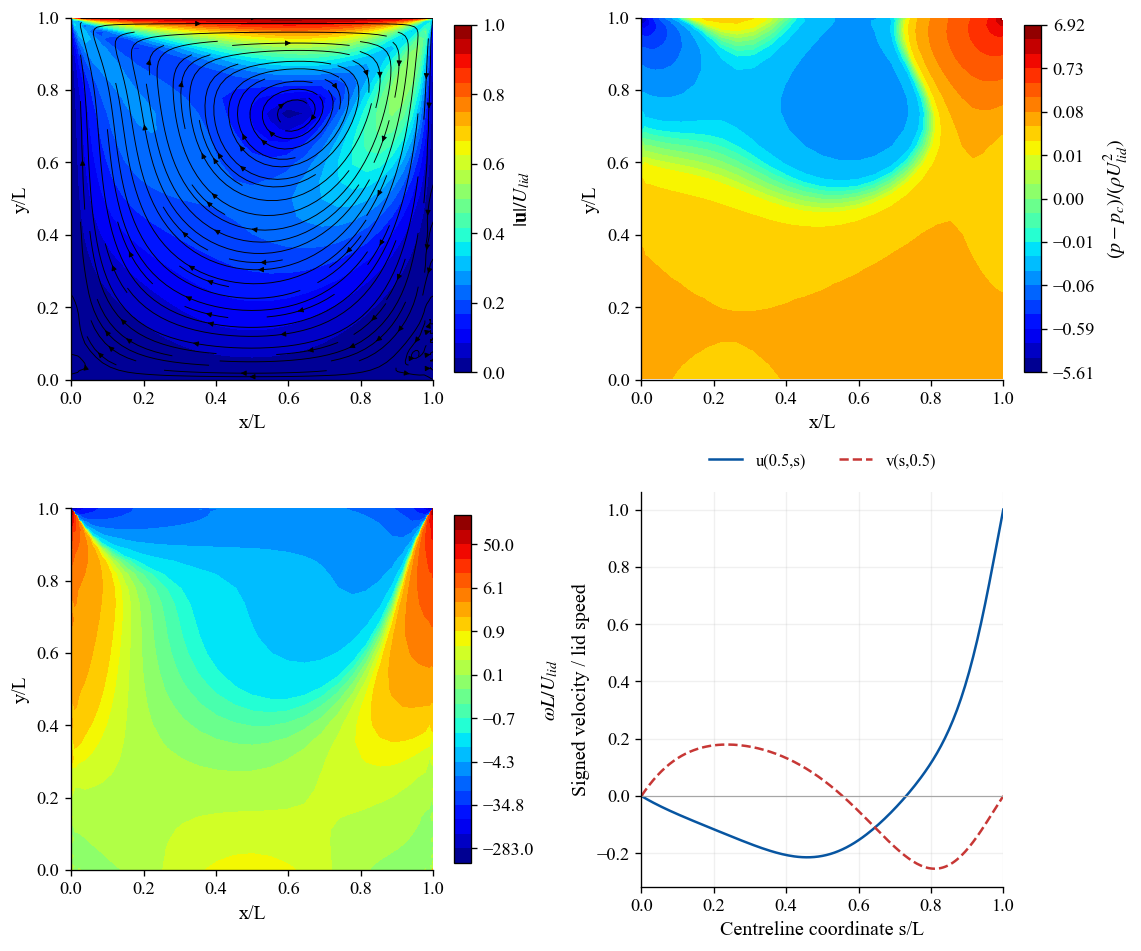

**Actual cavity: Re=400, N=32, 33×33 velocity nodes, lid `standard`.** Top left: speed and streamlines. Top right: pressure. Bottom left: signed vorticity. Bottom right: centreline velocities.

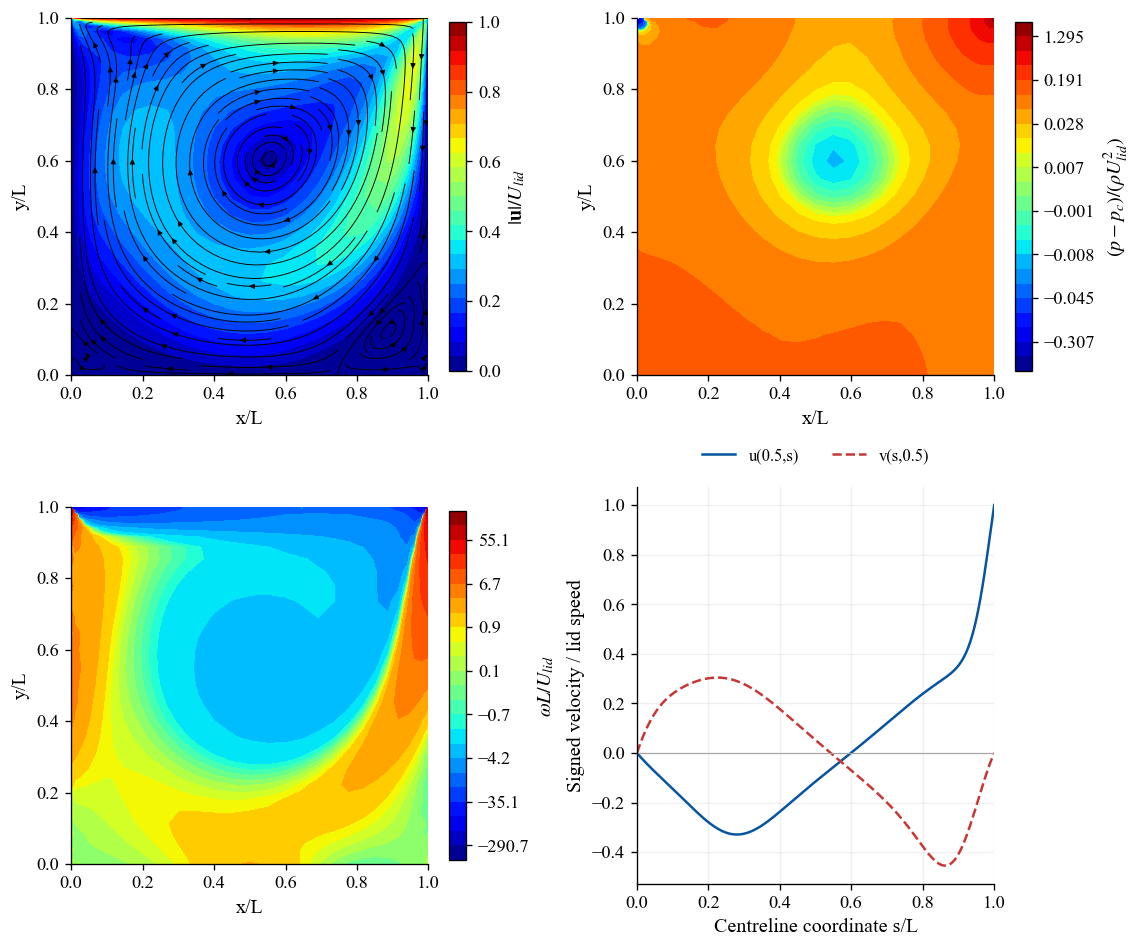

In [16]:
from matplotlib.colors import Normalize, SymLogNorm
from matplotlib.ticker import MaxNLocator
for re in CAVITY_REYNOLDS:
    n = max(CAVITY_DEGREES); sol = cavity_solutions[(re,n)]
    if not sol["converged"]:
        print(f"Skipping publication-style fields for unconverged Re={re}, N={n}"); continue
    x = sol["x"]; speed = np.hypot(sol["u"],sol["v"])
    pressure = sol["p"]
    omega = sol["omega"]
    fig, axes = plt.subplots(2,2,figsize=(9.4,7.9),layout="constrained")
    specifications = [(speed,x,r"$|\mathbf{u}|/U_{lid}$",None),
                      (pressure,x[1:-1],r"$(p-p_c)/(\rho U_{lid}^2)$",SymLogNorm(linthresh=.01,vmin=pressure.min(),vmax=pressure.max())),
                      (omega,x,r"$\omega L/U_{lid}$",SymLogNorm(linthresh=1,vmin=omega.min(),vmax=omega.max()))]
    for ax,(field,nodes,label,norm) in zip(axes.flat,specifications):
        if norm is None:
            levels = np.linspace(field.min(),field.max(),25)
        else:
            levels = norm.inverse(np.linspace(0,1,25))
        filled = ax.contourf(nodes,nodes,field,levels=levels,cmap="jet",norm=norm)
        cb = fig.colorbar(filled,ax=ax,shrink=.88,pad=.025)
        cb.set_label(label)
        if norm is None: cb.locator=MaxNLocator(nbins=5); cb.update_ticks()
        ax.set(xlabel="x/L",ylabel="y/L",xlim=(0,1),ylim=(0,1),aspect="equal")
    q = np.linspace(0,1,181)
    uq, vq = cavity_sample(sol,"u",q,q), cavity_sample(sol,"v",q,q)
    axes[0,0].streamplot(q,q,uq,vq,color="black",density=1.35,linewidth=.55,arrowsize=.65)
    ax=axes[1,1]
    ax.plot(q,cavity_sample(sol,"u",[.5],q)[:,0],color=COLORS[0],label="u(0.5,s)")
    ax.plot(q,cavity_sample(sol,"v",q,[.5])[0],color=COLORS[2],ls="--",label="v(s,0.5)")
    ax.axhline(0,color=".65",lw=.7); ax.grid(alpha=.18)
    ax.set(xlabel="Centreline coordinate s/L",ylabel="Signed velocity / lid speed",xlim=(0,1))
    ax.legend(loc="lower center",bbox_to_anchor=(.5,1.02),ncol=2,frameon=False)
    display(__import__('IPython').display.Markdown(
        f"**Actual cavity: Re={re}, N={n}, {(n+1)}×{(n+1)} velocity nodes, lid `{CAVITY_LID}`.** "
        "Top left: speed and streamlines. Top right: pressure. Bottom left: signed vorticity. Bottom right: centreline velocities."))
    save_figure(fig,f"cavity_fields_re{re}")

### 10.4 Compare with Ghia, then separate algebraic and spatial error

All curves below come from the just-computed fields. Reference markers remain at the original
Ghia coordinates; lines connect CFD evaluations on a dense centreline. The full per-sample signed
differences are in **Table G**. A flagged reference point is drawn as a cross rather than silently removed.
If the lid is changed to `smooth`, the Ghia comparison is disabled because its boundary condition differs.

The final diagnostic pairs the Newton residual history with the **signed off-grid divergence** along
y=0.95, x in [0.05,0.95]. The residual history is algebraic, and the line is a spatial check.
Reducing the former does not guarantee reducing the latter. Increasing N can help, but corner
singularities prevent us from promising exponential convergence for the standard discontinuous lid.

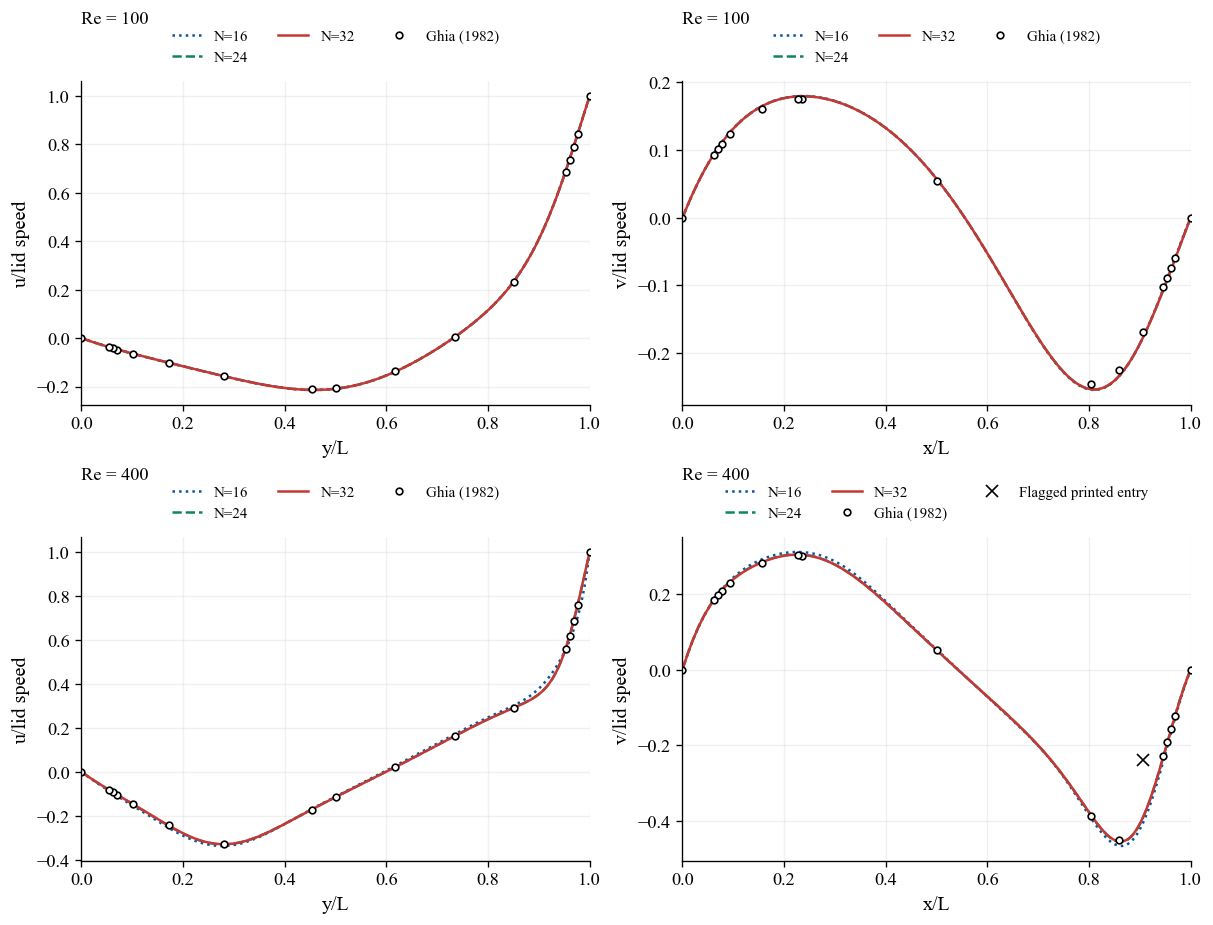

**Continuity and convergence diagnostics: Re=100.**

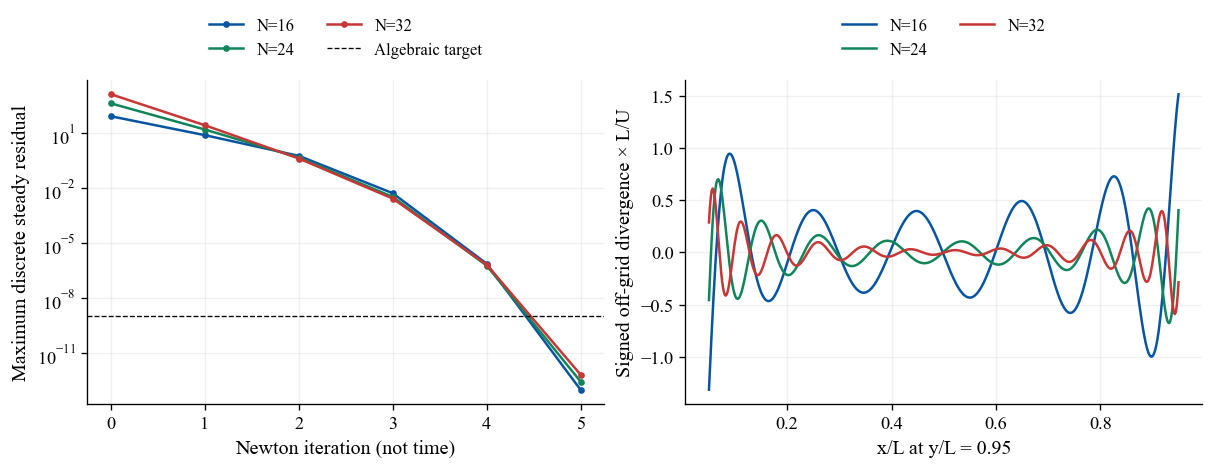

In [17]:
comparison_re = [re for re in CAVITY_REYNOLDS if re in GHIA_REFERENCE and CAVITY_LID == "standard"]
if comparison_re:
    fig,axes = plt.subplots(len(comparison_re),2,figsize=(10,3.8*len(comparison_re)),
                            squeeze=False,layout="constrained")
    q=np.linspace(0,1,501)
    for row,re in enumerate(comparison_re):
        ref=GHIA_REFERENCE[re]
        for j,component in enumerate(("u","v")):
            ax=axes[row,j]; coordinate="y" if component=="u" else "x"
            for k,n in enumerate(CAVITY_DEGREES):
                sol=cavity_solutions[(re,n)]
                pred=(cavity_sample(sol,"u",[.5],q)[:,0] if component=="u" else cavity_sample(sol,"v",q,[.5])[0])
                ax.plot(q,pred,color=COLORS[k%len(COLORS)],ls=[":","--","-"][k%3],label=f"N={n}")
            pos,val=np.asarray(ref[coordinate]),np.asarray(ref[component])
            flag=np.asarray(ref[component+"_flagged"],dtype=bool)
            ax.plot(pos[~flag],val[~flag],"ko",mfc="white",ms=4,label="Ghia (1982)")
            if flag.any(): ax.plot(pos[flag],val[flag],"x",color="black",ms=7,label="Flagged printed entry")
            ax.set(xlabel=f"{coordinate}/L",ylabel=f"{component}/lid speed",xlim=(0,1))
            ax.text(0,1.18,f"Re = {re}",transform=ax.transAxes,ha="left")
            ax.grid(alpha=.18)
            ax.legend(loc="lower center",bbox_to_anchor=(.5,1.01),ncol=3,fontsize=9,frameon=False)
    save_figure(fig,"cavity_ghia_profiles")

fig,axes=plt.subplots(1,2,figsize=(10,3.8),layout="constrained")
re=CAVITY_REYNOLDS[0]; q=np.linspace(.05,.95,501)
for k,n in enumerate(CAVITY_DEGREES):
    sol=cavity_solutions[(re,n)]; history=sol["history"]; color=COLORS[k%len(COLORS)]
    axes[0].semilogy(history[:,0],history[:,1],"o-",color=color,ms=3,label=f"N={n}")
    axes[1].plot(q,cavity_sample(sol,"divergence",q,[.95])[0],color=color,label=f"N={n}")
axes[0].axhline(CAVITY_TOLERANCE,color="black",ls="--",lw=.8,label="Algebraic target")
axes[0].set(xlabel="Newton iteration (not time)",ylabel="Maximum discrete steady residual")
axes[1].set(xlabel="x/L at y/L = 0.95",ylabel="Signed off-grid divergence × L/U")
for ax in axes:
    ax.grid(alpha=.18); ax.legend(loc="lower center",bbox_to_anchor=(.5,1.02),ncol=2,frameon=False)
display(__import__('IPython').display.Markdown(f"**Continuity and convergence diagnostics: Re={re}.**"))
save_figure(fig,"cavity_convergence_continuity")

### 10.5 What the comparison establishes

This is an actual steady cavity computation, with no body force, fresh velocity and pressure fields,
resolved wall values, a pressure gauge and explicit qualification criteria. The Ghia figures test
centreline velocities; they do not validate the pressure field or prove mesh independence.
Table C deliberately reports the disagreement and off-grid continuity defect rather than hiding them.

The DG implementation earlier in this notebook still solves the scalar transport equation.
It teaches numerical fluxes; **the cavity solver here is Chebyshev collocation, not a DG
Navier–Stokes solver**. Comparing a full DG cavity requires its viscous flux and compatible
incompressibility treatment. The separate Nektar++/ExaDG research runs are not used as notebook data.

The smooth lid $u_{lid}(x)=16x^2(1-x)^2$ is available for a controlled boundary-regularity exercise.
Its maximum speed is one, but its driving profile and lid-average speed differ from Ghia's.
Keep its results labelled and compare its own refinement sequence, never score it against the
standard-lid Ghia samples. No new high-Re or time-dependent-flow validation is claimed here.

## 11. Student investigations - submit evidence, not screenshots alone

Preserve the default tables. Create a copy of each table for your changed setting.
For every exercise write **prediction → controlled change → measured result → explanation**.
Use line/profile plots and a compact table. Explain failures; do not delete them.

1. **Interpolation and differentiation (Table A).** Add $q(x)=x^5$ and its exact derivative $5x^4$.
   Test N=4, 6, 12; use `d @ q(xc)` at nodes. Then differentiate the corner target away from
   x=0.37. Submit nodal derivative errors and explain polynomial exactness versus nonsmoothness.
2. **Choose an elliptic solver (Table P).** Extend FD to N=48 and 64 and Chebyshev to N=20.
   Find the smallest tested unknown count with relative field error below $10^{-3}$.
   Report residual, error, median/min/max time and memory implications; do not infer a general speedup.
3. **h versus p (Tables D and H).** Repeat the equal-64-coefficient comparison for both `smooth`
   and `localized`. Then repeat at 128 coefficients with K=128,64,32,16 and p=0,1,3,7.
   Compare signed errors, RHS calls and measured time. Explain why the best allocation can change.
4. **Flux and sharp fronts (Table F).** Add alpha=0.5. Keep K=24, p=3, C=0.12, t=0.35 fixed.
   Report minimum, maximum, mass drift and energy change. Show full profiles; do not clip overshoot.
   Explain why the least-dissipative option need not give the best field.
5. **Temporal qualification (Table T).** Repeat at K=16, p=5; compare C=0.12,0.06,0.03.
   Report the successive-difference ratio and total exact-solution errors. Distinguish a spatial plateau
   from failed temporal convergence. Change the final time only in a separate experiment.
6. **Conservation and direction.** Run the smooth target with a=-1. Verify the translation direction.
   Use `dg_diagnostics` to check mass; compare the same exact final-time field. Explain the sign in the flux.
7. **Compute and refine the cavity (Tables C and G).** At Re=100 add N=12 and 20 to N=16,24,32.
   Plot computed centreline velocities over Ghia samples, pressure at y=0.5 and signed vorticity
   at x=0.5. Compare successive fields at the same locations and the same pressure gauge.
   Report the all-sample errors and both continuity diagnostics. Identify which quantities have converged.
8. **Change Reynolds number, then the lid.** Compare standard-lid Re=100 and 400 at matched N.
   Describe changes in recirculation and wall gradients using computed flow fields. Retain the flagged
   Re=400 reference point and both score versions. In a separate run use `CAVITY_LID="smooth"` at Re=100;
   compare N=12,20,28 and its off-grid continuity. Explain why Ghia scoring is disabled for this run.
9. **Algebraic convergence versus CFD accuracy.** At Re=400,N=24 use tolerances 1e-5,1e-7,1e-9.
   Compare Newton iterations, residual history, Ghia errors and off-grid continuity. Then set the iteration
   budget to one to inspect an explicit failed-convergence record. Explain why a steady Newton iteration
   is not a time step and why tighter tolerances cannot repair under-resolution.

**Submission:** the executed notebook, revised Tables A/P/D/F/T/H/C/G as relevant, three decisive figures
(including actual cavity fields and a CFD-versus-Ghia comparison),
and a 400-600 word method recommendation with actual settings and limitations.
Assess numerical correctness, controlled comparisons and physical interpretation, not whether a named method wins.

## 12. Save evidence and further reading

The cell below saves the current numerical tables and a compact configuration record beside the figures.
Use Restart and Run All before submitting. Saved outputs document one execution; your own changed
controls must be rerun. No cached CFD field is substituted for a fresh computation.

1. L. N. Trefethen, *Spectral Methods in MATLAB*, SIAM (2000).
   [Author's short programs and chapters](https://people.maths.ox.ac.uk/trefethen/spectral.html).
2. J. S. Hesthaven and T. Warburton, *Nodal Discontinuous Galerkin Methods*, Springer (2008).
   [Book DOI](https://doi.org/10.1007/978-0-387-72067-8). Our code uses modal Legendre coefficients;
   the weak-form and numerical-flux principles are shared with nodal DG.
3. deal.II, [Step 12: discontinuous Galerkin advection](https://dealii.org/9.7.0/doxygen/deal.II/step_12.html).
   This is an external 2-D adaptive-mesh extension, not a dependency of this notebook.
4. S. Gottlieb and C.-W. Shu, *Total variation diminishing Runge-Kutta schemes*, Math. Comp. 67 (1998), 73-85.
   [DOI](https://doi.org/10.1090/S0025-5718-98-00913-2).

The small algorithms here are independently written for FlowMLLab from the displayed equations.
5. Ghia, Ghia and Shin (1982), [original cavity benchmark](https://doi.org/10.1016/0021-9991(82)90058-4),
   Tables I and II. [Repository transcription and flagged-entry policy](../../references/ghia/README.md).
6. Botella and Peyret (1998), [Benchmark spectral results on the lid-driven cavity flow](https://doi.org/10.1016/S0045-7930(98)00002-4).
   Their high-accuracy singularity treatment is not implemented in this small teaching solver.
7. Botella and Peyret (2001), [Computing singular solutions with Chebyshev collocation](https://doi.org/10.1002/fld.121).
   Background on the mixed pressure/velocity spaces and corner singularities; our code uses a direct steady Newton solve.

Polynomial, Poisson, conservation and DG refinement checks are in `tests/test_high_order.py`.
`tests/test_high_order_cavity.py` independently tests a manufactured full Navier–Stokes solution,
the exact Jacobian, wall and pressure-gauge conditions, Ghia comparisons and failed-convergence reporting.

In [18]:
tables = {"A":table_a, "P":table_p, "D":table_d, "F":table_f, "T":table_t, "H":table_h,
          "C":table_c, "G":table_g}
for label, table in tables.items():
    table.to_csv(OUTPUT_DIR / f"table_{label}.csv", index=False)
evidence = {"unit":"1.4", "problem_roles":["manufactured Dirichlet Poisson", "periodic linear scalar transport", "steady incompressible driven cavity"],
            "python":platform.python_version(), "numpy":np.__version__, "scipy":scipy.__version__,
            "platform":platform.platform(), "processor":platform.processor(),
            "controls":{"degrees":DEGREES,"poisson_n":POISSON_N,"timing_repeats":TIMING_REPEATS,
                        "dg_cases":DG_CASES,"target":TARGET,"speed":SPEED,"final_time":FINAL_TIME,
                        "cfl":CFL,"alpha":ALPHA,"flux_k":FLUX_K,"flux_p":FLUX_P,
                        "cavity_reynolds":CAVITY_REYNOLDS,"cavity_degrees":CAVITY_DEGREES,
                        "cavity_tolerance":CAVITY_TOLERANCE,"cavity_max_iterations":CAVITY_MAX_ITERATIONS,
                        "cavity_lid":CAVITY_LID},
            "ghia_source_sha256":GHIA_SOURCE_SHA256,"ghia_source_doi":GHIA_DOI,
            "time_difference_ratio":float(time_ratio),
            "elapsed_cells_seconds":perf_counter()-RUN_STARTED,
            "figures":FIGURES, "tables":{k:v.astype(object).where(pd.notna(v),None).to_dict(orient="records") for k,v in tables.items()}}
(OUTPUT_DIR / "execution.json").write_text(json.dumps(evidence, indent=2, allow_nan=False), encoding="utf-8")
print("Saved", len(tables), "tables and", len(FIGURES), "figures to", OUTPUT_DIR)
print("Elapsed experiment/plotting time (s):", round(evidence["elapsed_cells_seconds"], 2))

Saved 8 tables and 11 figures to D:\ChatGPT Backup\Projects\FlowMLLab\Teaching_Current\repo\results\week01_4_spectral_dg
Elapsed experiment/plotting time (s): 114.48
